# 00 — Analyse exploratoire & découpage du jeu de données

**Projet DiagnoCulture** — diagnostic des maladies de la tomate par apprentissage profond.  
*Version Google Colab (GPU T4).* Le dataset est récupéré via **kagglehub** (cache effacé à chaque session) ; les livrables `split.csv` et `norm_stats.json` sont enregistrés sur **Google Drive** pour être réutilisés d'une session à l'autre.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Localisation du dataset

**Montage de Google Drive (stockage persistant) et téléchargement du dataset via kagglehub.** Le cache kagglehub est temporaire — seul Drive conserve les fichiers d'une session à l'autre.

In [ ]:
import os, json
import pandas as pd
import kagglehub
from google.colab import drive

# 1) Drive = stockage persistant (le cache kagglehub est effacé à chaque session)
drive.mount('/content/drive')
PROJ = "/content/drive/MyDrive/Colab_Notebooks/Note_MSID1/DeepLearning/PROJECT"   # <-- ton dossier Drive
os.makedirs(PROJ, exist_ok=True)

# 2) Dataset via kagglehub (chemin TEMPORAIRE, change à chaque session)
base = kagglehub.dataset_download("emmarex/plantdisease")
print("Dataset téléchargé dans :", base)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset téléchargé dans : /kaggle/input/plantdisease


**Détection de la racine des classes.** On descend l'arborescence jusqu'au dossier contenant les dossiers `Tomato…`, puis on fige la liste triée des classes (ordre = codes 0→9).

In [ ]:
# arborescence du dataset : .../PlantVillage/Tomato...
DATA_ROOT = None
for r, d, _ in os.walk(base):
    if any(x.startswith("Tomato") for x in d):
        DATA_ROOT = r
        break

classes = sorted(c for c in os.listdir(DATA_ROOT) if c.startswith("Tomato"))
print("DATA_ROOT =", DATA_ROOT)
print(len(classes), "classes Tomato")

DATA_ROOT = /kaggle/input/plantdisease/PlantVillage
10 classes Tomato


**Résultat.** Racine = `/kaggle/input/plantdisease/PlantVillage`, **10 classes** `Tomato` détectées (9 maladies + feuilles saines).

## 2. Distribution des classes

**Comptage des images par classe.**

In [ ]:
classes = sorted([d for d in os.listdir(DATA_ROOT) if d.startswith("Tomato")])

total = 0
for c in classes:
    n = len(os.listdir(os.path.join(DATA_ROOT, c)))
    total += n
    print(f"{n:5d}  {c}")

print("-" * 40)
print(f"{total:5d}  TOTAL")

 2127  Tomato_Bacterial_spot
 1000  Tomato_Early_blight
 1909  Tomato_Late_blight
  952  Tomato_Leaf_Mold
 1771  Tomato_Septoria_leaf_spot
 1676  Tomato_Spider_mites_Two_spotted_spider_mite
 1404  Tomato__Target_Spot
 3209  Tomato__Tomato_YellowLeaf__Curl_Virus
  373  Tomato__Tomato_mosaic_virus
 1591  Tomato_healthy
----------------------------------------
16012  TOTAL


**Résultat.** 16 012 images au total, mais distribution **très déséquilibrée** : de 373 images (`mosaic_virus`) à 3 209 (`YellowLeaf_Curl_Virus`), soit un rapport ~8,6×. À gérer à l'entraînement (pondération) et à l'évaluation (F1-macro).

**Visualisation de la distribution.**

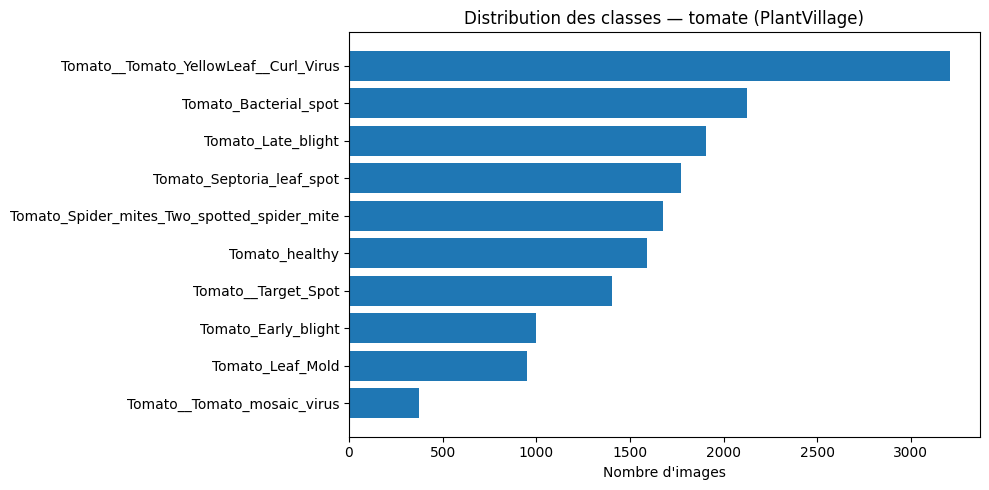

In [ ]:
import matplotlib.pyplot as plt

counts = {c: len(os.listdir(os.path.join(DATA_ROOT, c))) for c in classes}
counts = dict(sorted(counts.items(), key=lambda x: x[1], reverse=True))

plt.figure(figsize=(10, 5))
plt.barh(list(counts.keys()), list(counts.values()))
plt.xlabel("Nombre d'images")
plt.title("Distribution des classes — tomate (PlantVillage)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Résultat.** Le diagramme confirme le déséquilibre : deux classes dominent nettement, deux sont sous-représentées.

## 3. Inventaire du dataset (DataFrame)

Tableau complet — **une ligne par image** — avec le chemin, la classe et l'indice `class_idx`. Le chemin est stocké **relatif à `DATA_ROOT`** : ainsi `split.csv` reste valable même quand le cache kagglehub change d'une session à l'autre.

**Définition de `scan_dataset`.** Ne retient que les vrais fichiers image et stocke un chemin **relatif**.

In [ ]:
def scan_dataset(root):
    # classes = sous-dossiers "Tomato...", triés -> ordre FIGÉ
    classes = sorted(
        d for d in os.listdir(root)
        if os.path.isdir(os.path.join(root, d)) and d.startswith("Tomato")
    )
    class_to_idx = {c: i for i, c in enumerate(classes)}

    rows = []
    exts_ok = {".jpg", ".jpeg", ".png"}
    for c in classes:
        i = class_to_idx[c]
        dossier = os.path.join(root, c)
        for f in os.listdir(dossier):
            ext = os.path.splitext(f)[1].lower()
            if ext in exts_ok:
                rows.append({
                    "path": os.path.relpath(os.path.join(dossier, f), root),  # RELATIF à DATA_ROOT
                    "label": c,
                    "class_idx": i,
                })
    return pd.DataFrame(rows), class_to_idx

**Aperçu du résultat de `scan_dataset`.**

In [ ]:
scan_dataset(DATA_ROOT)

**Résultat.** DataFrame (`path`, `label`, `class_idx`) + dictionnaire `class_to_idx` figé de 0 à 9. Les chemins sont désormais **relatifs** (ex. `Tomato_healthy/xxxx.jpg`).

**Construction définitive de l'inventaire et contrôle des effectifs.**

In [ ]:
df, class_to_idx = scan_dataset(DATA_ROOT)
print(df.shape)
df["label"].value_counts()

**Résultat.** 16 011 images retenues, soit **1 de moins** que le comptage brut : un fichier non-image écarté par le filtre d'extensions. Le déséquilibre est re-confirmé.

## 4. Contrôle anti-fuite (perceptual hash)

PlantVillage contient parfois la **même feuille** sous plusieurs formes. Si une copie tombe en *train* et sa jumelle en *test*, le score de test est **gonflé artificiellement** (fuite). On calcule un **pHash** par image pour repérer les quasi-doublons.

**Installation de `imagehash`.**

In [ ]:
!pip install imagehash

**Résultat.** `imagehash` installé.

**Calcul de l'empreinte pHash (64 bits) de chaque image** — on reconstruit le chemin absolu à partir du chemin relatif + `DATA_ROOT`.

In [ ]:
import imagehash
from PIL import Image
from tqdm import tqdm

def add_phash(df):
    hashes = []
    for p in tqdm(df["path"]):
        img = Image.open(os.path.join(DATA_ROOT, p)).convert("RGB")  # relatif -> absolu
        h = imagehash.phash(img)
        hashes.append(str(h))
    df = df.copy()
    df["phash"] = hashes
    return df

**Comptage des doublons visuels.**

In [ ]:
df = add_phash(df)
print("images       :", len(df))
print("hash uniques :", df["phash"].nunique())
print("doublons     :", len(df) - df["phash"].nunique())

**Résultat.** 16 011 images → 15 997 empreintes uniques : seulement **14 quasi-doublons**. Jeu très propre.

**Vérification cruciale : un doublon touche-t-il deux classes différentes ?**

In [ ]:
# on isole les images dont le hash apparaît plus d'une fois
dups = df[df["phash"].duplicated(keep=False)]

# pour chaque hash en double, combien de classes différentes ?
print(dups.groupby("phash")["label"].nunique().value_counts())

**Résultat.** Les 14 doublons appartiennent tous à **une seule classe**. Aucune fuite inter-classes : on peut les retirer sans risque.

**Suppression des doublons** (on garde la première occurrence).

In [ ]:
clean_data = df.drop_duplicates(subset="phash", keep="first").reset_index(drop=True)
print("images après dédup :", len(clean_data))

**Résultat.** 15 997 images conservées après déduplication.

## 5. Découpage stratifié train / val / test

**Fonction de découpage.** 70 % / 15 % / 15 %, **stratifié par classe**. Le `0.15/0.85` assure que la validation vaut bien 15 % du total.

In [ ]:
from sklearn.model_selection import train_test_split

def make_split(clean_data, seed=42):
    clean_data = clean_data.copy()

    # 1) on retire le TEST (15 % du total)
    train_val, test = train_test_split(
        clean_data, test_size=0.15, stratify=clean_data["class_idx"], random_state=seed
    )

    # 2) on retire la VALIDATION depuis les 85 % restants.
    #    val doit valoir 15 % du TOTAL -> 0.15/0.85 de ce qui reste
    train, val = train_test_split(
        train_val, test_size=0.15/0.85, stratify=train_val["class_idx"], random_state=seed
    )

    # 3) on marque chaque image
    clean_data["split"] = "train"
    clean_data.loc[val.index,  "split"] = "val"
    clean_data.loc[test.index, "split"] = "test"
    return clean_data

**Application et contrôle des proportions.**

In [ ]:
clean_data = make_split(clean_data)

print(clean_data["split"].value_counts(normalize=True).round(3))

# vérif que CHAQUE classe respecte 70/15/15
pd.crosstab(clean_data["label"], clean_data["split"], normalize="index").round(3)

**Résultat.** 70/15/15 respecté globalement, et le `crosstab` montre que **chaque classe** suit ces proportions.

**Sauvegarde du découpage figé sur Drive (`PROJ/split.csv`).** Chemins relatifs → réutilisable à chaque session malgré le changement du cache kagglehub.

In [ ]:
cols = ["path", "label", "class_idx", "split"]
split_path = os.path.join(PROJ, "split.csv")
clean_data[cols].to_csv(split_path, index=False)
print("split.csv sauvegardé sur Drive :", split_path, "|", len(clean_data), "lignes")

# vérif qu'il se recharge bien
check = pd.read_csv(split_path)
print(check["split"].value_counts())

**Résultat.** 15 997 lignes sur Drive (train 11 197 / val 2 400 / test 2 400), rechargement vérifié.

## 6. Statistiques de normalisation

**Moyenne et écart-type par canal RGB — sur le TRAIN uniquement** (pas de fuite depuis val/test).

In [ ]:
import numpy as np

def compute_norm_stats(clean_data, img_size=128):
    paths = clean_data[clean_data["split"] == "train"]["path"].values   # TRAIN seulement
    somme    = np.zeros(3)
    somme_sq = np.zeros(3)
    n_pixels = 0
    for p in tqdm(paths):
        img = Image.open(os.path.join(DATA_ROOT, p)).convert("RGB").resize((img_size, img_size))
        x = np.asarray(img, dtype=np.float64) / 255.0
        somme    += x.sum(axis=(0, 1))
        somme_sq += (x ** 2).sum(axis=(0, 1))
        n_pixels += x.shape[0] * x.shape[1]
    mean = somme / n_pixels
    std  = np.sqrt(somme_sq / n_pixels - mean ** 2)
    return mean, std

**Exécution du calcul.**

In [ ]:
mean, std = compute_norm_stats(clean_data, img_size=128)
print("mean:", mean)
print("std :", std)


**Résultat.** mean ≈ [0.451, 0.465, 0.407], std ≈ [0.178, 0.155, 0.193] sur les 11 197 images d'entraînement.

**Sauvegarde des statistiques sur Drive (`PROJ/norm_stats.json`).**

In [ ]:
norm_path = os.path.join(PROJ, "norm_stats.json")
with open(norm_path, "w") as f:
    json.dump({"mean": mean.tolist(), "std": std.tolist()}, f)
print("norm_stats.json sauvegardé sur Drive :", norm_path)

**Résultat.** Statistiques enregistrées sur Drive, réutilisables tel quel (ce sont de simples nombres).

## 7. Dataset & DataLoader PyTorch

On emballe les images dans un `Dataset` (`LeafDataset`) + des `DataLoader`. Augmentation (miroir horizontal) sur le **train uniquement**.

**(Optionnel) Reprise depuis Drive dans une nouvelle session.**

In [ ]:
# Pour relancer à partir d'ici (nouvelle session Colab) :
#  1) ré-exécuter la cellule de SETUP (drive + kagglehub) -> on récupère PROJ et DATA_ROOT
#  2) puis décommenter :
clean_data = pd.read_csv(os.path.join(PROJ, "split.csv"))
with open(os.path.join(PROJ, "norm_stats.json")) as f:
    stats = json.load(f)
mean, std = stats["mean"], stats["std"]
print(clean_data.shape, "| mean:", mean, "| std:", std)

(15997, 4) | mean: [0.4510954204684638, 0.4649513691038557, 0.4072063214449523] | std: [0.1781187912422103, 0.15549914738434029, 0.1930529174089212]


**Définition du `LeafDataset`.** Reconstruit le chemin absolu (`DATA_ROOT` + chemin relatif), puis redimensionne + normalise (+ miroir horizontal pour le train).

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

class LeafDataset(Dataset):
    def __init__(self, df, split, img_size, mean, std, augment=False):
        self.df = df[df["split"] == split].reset_index(drop=True)

        tfms = [transforms.Resize((img_size, img_size))]
        if augment:                                   # train uniquement
            tfms += [transforms.RandomHorizontalFlip()]
        tfms += [
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ]
        self.tf = transforms.Compose(tfms)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, row["path"])).convert("RGB")  # relatif -> absolu
        x = self.tf(img)
        y = int(row["class_idx"])
        return x, y

**Création des `Dataset` et `DataLoader`** (augmentation sur le train seulement). Sur Colab on peut utiliser `num_workers=2` + `pin_memory=True` pour accélérer l'alimentation du GPU.

In [ ]:
IMG = 128   # résolution des CNN maison

train_ds = LeafDataset(clean_data, "train", IMG, mean, std, augment=True)
val_ds   = LeafDataset(clean_data, "val",   IMG, mean, std, augment=False)
test_ds  = LeafDataset(clean_data, "test",  IMG, mean, std, augment=False)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

**Vérification d'un batch.**

In [ ]:
images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

torch.Size([32, 3, 128, 128]) torch.Size([32])


**Résultat.** Un batch = `torch.Size([32, 3, 128, 128])` + `[32]` labels : format `(N, C, H, W)` attendu par le CNN.

## 8. Modèle de référence — CNN-Plain

**Architecture du CNN maison.** 6 blocs `Conv → BatchNorm → ReLU → MaxPool` ramenant 128×128 à 2×2, puis tête dense 1024 → 256 → 10.

In [ ]:
import torch.nn as nn

class CNNPlain(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        # 6 convolutions : noyau 3, padding 1 -> la conv conserve la taille
        self.conv1 = nn.Conv2d(3,   32,  kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32,  64,  kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64,  128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv6 = nn.Conv2d(256, 256, kernel_size=3, padding=1)

        # une BatchNorm par conv normaliser
        self.bn1 = nn.BatchNorm2d(32)
        self.bn2 = nn.BatchNorm2d(64)
        self.bn3 = nn.BatchNorm2d(128)
        self.bn4 = nn.BatchNorm2d(128)
        self.bn5 = nn.BatchNorm2d(256)
        self.bn6 = nn.BatchNorm2d(256)

        self.pool    = nn.MaxPool2d(2)   # divise la taille par 2
        self.relu    = nn.ReLU()
        self.flatten = nn.Flatten()

        # tête dense : 256 canaux * 2 * 2 = 1024
        self.fc1     = nn.Linear(256 * 2 * 2, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2     = nn.Linear(256, num_classes)

    def forward(self, x):
        # entrée : (N, 3, 128, 128)
        x = self.pool(self.relu(self.bn1(self.conv1(x))))   # -> (N,  32, 64, 64)
        x = self.pool(self.relu(self.bn2(self.conv2(x))))   # -> (N,  64, 32, 32)
        x = self.pool(self.relu(self.bn3(self.conv3(x))))   # -> (N, 128, 16, 16)
        x = self.pool(self.relu(self.bn4(self.conv4(x))))   # -> (N, 128,  8,  8)
        x = self.pool(self.relu(self.bn5(self.conv5(x))))   # -> (N, 256,  4,  4)
        x = self.pool(self.relu(self.bn6(self.conv6(x))))   # -> (N, 256,  2,  2)

        x = self.flatten(x)              # -> (N, 1024)
        x = self.relu(self.fc1(x))       # -> (N, 256)
        x = self.dropout(x)
        x = self.fc2(x)                  # -> (N, 10)
        return x

model = CNNPlain()

**Résumé des dimensions et du nombre de paramètres.**

In [ ]:
!pip install torchinfo

In [ ]:
from torchinfo import summary

summary(model, input_size=(1, 3, 128, 128))

Layer (type:depth-idx)                   Output Shape              Param #
CNNPlain                                 [1, 10]                   --
├─Conv2d: 1-1                            [1, 32, 128, 128]         896
├─BatchNorm2d: 1-2                       [1, 32, 128, 128]         64
├─ReLU: 1-3                              [1, 32, 128, 128]         --
├─MaxPool2d: 1-4                         [1, 32, 64, 64]           --
├─Conv2d: 1-5                            [1, 64, 64, 64]           18,496
├─BatchNorm2d: 1-6                       [1, 64, 64, 64]           128
├─ReLU: 1-7                              [1, 64, 64, 64]           --
├─MaxPool2d: 1-8                         [1, 64, 32, 32]           --
├─Conv2d: 1-9                            [1, 128, 32, 32]          73,856
├─BatchNorm2d: 1-10                      [1, 128, 32, 32]          256
├─ReLU: 1-11                             [1, 128, 32, 32]          --
├─MaxPool2d: 1-12                        [1, 128, 16, 16]          --
├─Co

**Résultat.** 1,39 M paramètres (~5,6 Mo). Les dimensions descendent de (3, 128, 128) à (256, 2, 2) puis 10 sorties.

## 9. Préparation de l'entraînement

**Choix du device, de la fonction de perte et de l'optimiseur.** `CrossEntropyLoss` + Adam (lr = 1e-3).

In [ ]:
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print("device:", device)

criterion = nn.CrossEntropyLoss()                        # perte pour classif multi-classes
optimizer = optim.Adam(model.parameters(), lr=1e-3)      # optimiseur robuste, lr standard

device: cuda


**Résultat.** `device: cuda` → entraînement sur le **GPU Colab (T4)** 🚀. Si jamais ça repasse sur CPU : *Exécution → Modifier le type d'exécution → T4 GPU*.

## 10. Entraînement (à venir)

Cellule réservée à la boucle d'entraînement train/val (early-stopping, courbes de perte), puis à l'évaluation sur le test (matrice de confusion, F1-macro).

In [ ]:
import copy, time, torch

torch.manual_seed(42)      # reproductibilité (init des poids + shuffle)

EPOCHS   = 30
PATIENCE = 5               # on arrête si val_loss ne s'améliore plus pendant 5 epochs

history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_loss = float("inf")
best_weights  = copy.deepcopy(model.state_dict())
patience_cnt  = 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    # ---------- TRAIN ----------
    model.train()
    running = 0.0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * x.size(0)
    train_loss = running / len(train_loader.dataset)

    # ---------- VALIDATION ----------
    model.eval()
    v_running, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            v_running += criterion(out, y).item() * x.size(0)
            correct   += (out.argmax(1) == y).sum().item()
            total     += y.size(0)
    val_loss = v_running / len(val_loader.dataset)
    val_acc  = correct / total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    print(f"Epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f} | val_acc {val_acc:.3f} | {time.time()-t0:.0f}s")

    # ---------- EARLY-STOPPING ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights  = copy.deepcopy(model.state_dict())
        patience_cnt  = 0
    else:
        patience_cnt += 1
        if patience_cnt >= PATIENCE:
            print(f"Early-stopping à l'epoch {epoch}")
            break

model.load_state_dict(best_weights)                       # on restaure le meilleur modèle
torch.save(best_weights, os.path.join(PROJ, "cnn_plain_best.pt"))   # sauvé sur Drive
print("Meilleur val_loss :", round(best_val_loss, 4))

Epoch  1 | train 1.0181 | val 0.5104 | val_acc 0.810 | 58s
Epoch  2 | train 0.5452 | val 0.4599 | val_acc 0.831 | 31s
Epoch  3 | train 0.4221 | val 0.2815 | val_acc 0.907 | 32s
Epoch  4 | train 0.3554 | val 0.2605 | val_acc 0.918 | 31s
Epoch  5 | train 0.3045 | val 0.2781 | val_acc 0.905 | 31s
Epoch  6 | train 0.2686 | val 0.2084 | val_acc 0.935 | 31s
Epoch  7 | train 0.2338 | val 0.1685 | val_acc 0.943 | 31s
Epoch  8 | train 0.1937 | val 0.1184 | val_acc 0.960 | 32s
Epoch  9 | train 0.1950 | val 0.1568 | val_acc 0.946 | 31s
Epoch 10 | train 0.1634 | val 0.1946 | val_acc 0.933 | 31s
Epoch 11 | train 0.1618 | val 0.2859 | val_acc 0.922 | 31s
Epoch 12 | train 0.1409 | val 0.1155 | val_acc 0.965 | 32s
Epoch 13 | train 0.1212 | val 0.1002 | val_acc 0.965 | 32s
Epoch 14 | train 0.1240 | val 0.1942 | val_acc 0.939 | 31s
Epoch 15 | train 0.1142 | val 0.1008 | val_acc 0.965 | 31s
Epoch 16 | train 0.1053 | val 0.1655 | val_acc 0.946 | 32s
Epoch 17 | train 0.1058 | val 0.1309 | val_acc 0.958 | 3

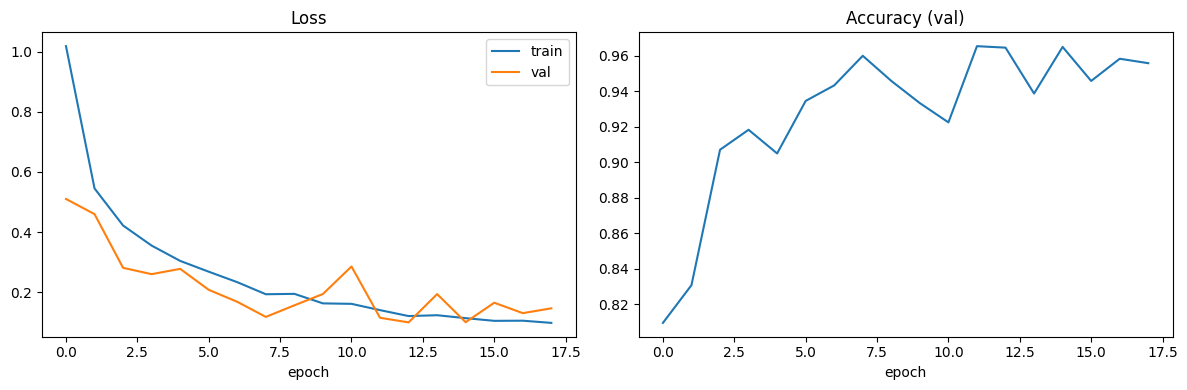

In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history["train_loss"], label="train")
ax1.plot(history["val_loss"],   label="val")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(history["val_acc"])
ax2.set_title("Accuracy (val)"); ax2.set_xlabel("epoch")
plt.tight_layout(); plt.show()

Accuracy  : 0.964
F1-macro  : 0.961

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot      0.927     0.997     0.961       319
                        Tomato_Early_blight      0.913     0.913     0.913       150
                         Tomato_Late_blight      0.985     0.944     0.964       285
                           Tomato_Leaf_Mold      0.923     1.000     0.960       143
                  Tomato_Septoria_leaf_spot      0.984     0.944     0.964       266
Tomato_Spider_mites_Two_spotted_spider_mite      0.968     0.964     0.966       251
                        Tomato__Target_Spot      0.926     0.953     0.939       211
      Tomato__Tomato_YellowLeaf__Curl_Virus      0.998     0.958     0.978       481
                Tomato__Tomato_mosaic_virus      0.949     1.000     0.974        56
                             Tomato_healthy      0.996     0.987     0.992       238

                          

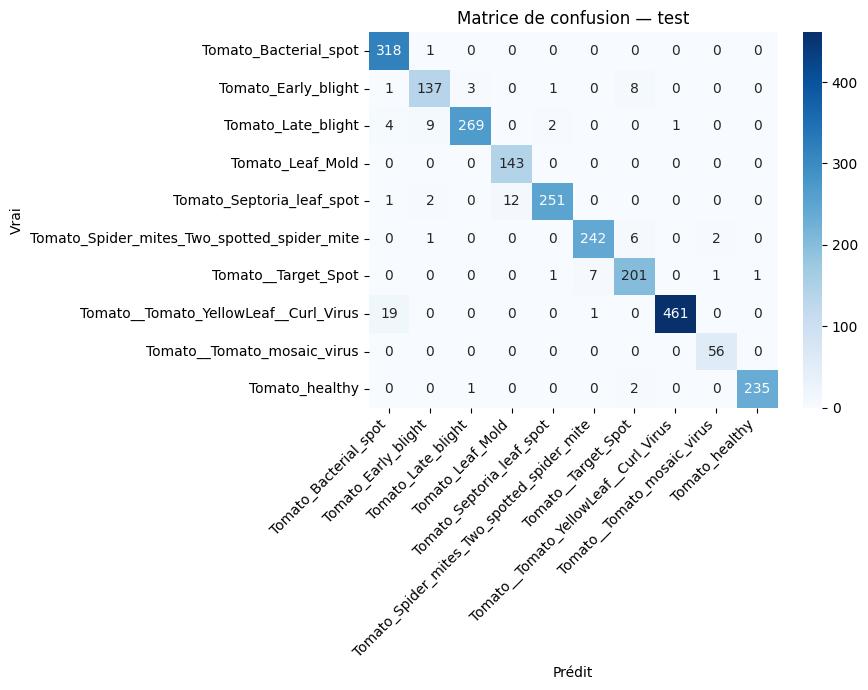

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import numpy as np, seaborn as sns, matplotlib.pyplot as plt

model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        out = model(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

acc = accuracy_score(y_true, y_pred)
f1m = f1_score(y_true, y_pred, average="macro")
print(f"Accuracy  : {acc:.3f}")
print(f"F1-macro  : {f1m:.3f}")
print()
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.xlabel("Prédit"); plt.ylabel("Vrai"); plt.title("Matrice de confusion — test")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()